# EdNet × Santa — làm lại từ nguồn

Không dùng mapping cũ. Notebook đi qua kiểm kê → match → tỷ lệ → mapping thô → nhóm cha. Đọc `docs/PIPELINE.md` và `docs/RESULTS.md` để biết công thức, số liệu và giới hạn.

**Không có gold accuracy. Part 1 không được xem như đã match câu nếu chỉ có lecture bridge.**

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd().resolve()
if not (ROOT / 'config/policy.json').exists():
    ROOT = ROOT.parent
assert (ROOT / 'src/pipeline.py').exists(), 'Open notebook from this repository'
sys.path.insert(0, str(ROOT))
REBUILD = False
if REBUILD:
    from src.pipeline import run
    run()
OUT = ROOT / 'outputs'
assert (OUT / 'summary.json').exists(), 'Run python -m src.pipeline first'
load = lambda name: json.loads((OUT / name).read_text(encoding='utf-8'))
summary = load('summary.json')
mapping = load('tag_mapping.json')
matched = pd.DataFrame(load('matched_questions.json'))
rates = pd.read_csv(OUT / 'tag_label_rates.csv')
decisions = pd.read_csv(OUT / 'mapping_decisions.csv')
names = load('label_names.json')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
print('Snapshot:', summary['snapshot'])

Snapshot: 4b3bc468a01c1bcccae3acac2a27d322fa94360bc98bd121055988b3a6966161


## 1. Data có gì?

Nguồn duy nhất là raw content và hai CSV EdNet trong repo. Trường tự suy ra chỉ nằm trong outputs; raw không bị sửa.

,count
reference_questions,13169
reference_tags,188
raw_content_files,4250
crawl_question_occurrences,5500
crawl_unique_questions,5470
lecture_matches,287


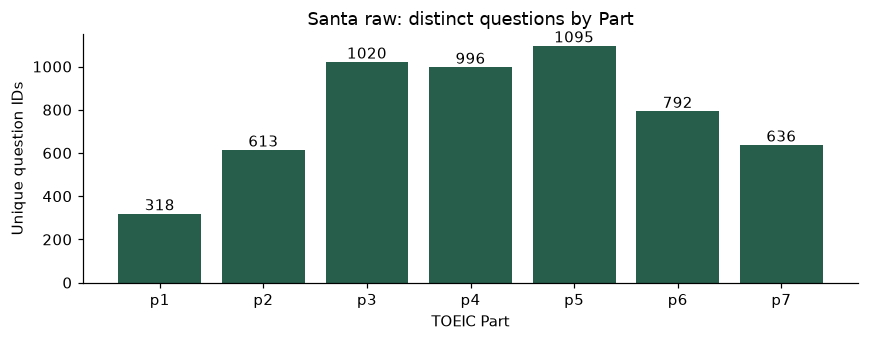

In [2]:
inventory = pd.Series({k: summary[k] for k in ['reference_questions','reference_tags','raw_content_files','crawl_question_occurrences','crawl_unique_questions','lecture_matches']}, name='count')
display(inventory.to_frame())
fig, ax = plt.subplots(figsize=(8,3.2))
parts = summary['crawl_questions_by_part']
ax.bar(sorted(parts), [parts[p] for p in sorted(parts)], color='#275d4b')
ax.set(xlabel='TOEIC Part', ylabel='Unique question IDs', title='Santa raw: distinct questions by Part')
for i,p in enumerate(sorted(parts)): ax.text(i, parts[p], str(parts[p]), ha='center', va='bottom')
fig.tight_layout(); plt.show()

## 2. Match ID và kiểm tra nối

Từng cổng kiểm tra giữ số liệu riêng. Chỉ strict matches được dùng đo tỷ lệ. Trùng ID không đủ chứng minh cùng câu. Không ép UUID về ID số.

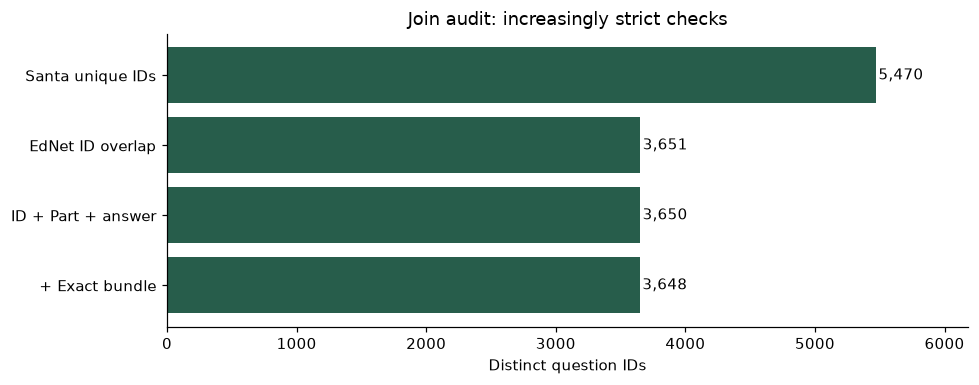

,question_id,source_raw,part,answer,bundle
0,q7256,data/raw/santa/full/part7/raw/toeic_test_conte...,True,False,True
1,q7776,data/raw/santa/full/part7/raw/toeic_test_conte...,True,True,False
2,q7777,data/raw/santa/full/part7/raw/toeic_test_conte...,True,True,False


Matched Part 1: 0


In [3]:
funnel = pd.Series({'Santa unique IDs':summary['crawl_unique_questions'], 'EdNet ID overlap':summary['id_overlap'], 'ID + Part + answer':summary['three_key_matches'], '+ Exact bundle':summary['strict_question_matches']})
fig, ax = plt.subplots(figsize=(9,3.6))
ax.barh(funnel.index[::-1], funnel.values[::-1], color='#275d4b')
for i,v in enumerate(funnel.values[::-1]): ax.text(v+20, i, f'{v:,}', va='center')
ax.set(xlabel='Distinct question IDs', title='Join audit: increasingly strict checks'); ax.set_xlim(0,max(funnel.values)*1.13)
fig.tight_layout(); plt.show()
audit = load('join_audit.json')
display(pd.DataFrame(audit['rejected_variants']))
assert matched.question_id.is_unique
print('Matched Part 1:', int((matched.part == 'p1').sum()))

## 3. Nhãn thô đến từ đâu?

Các trục task / grammar / topic / format / accent được tách riêng. Xem config để sửa độ chi tiết. Mã metadata lặp giữa chapter và chapterList chỉ đếm một lần.

In [4]:
families = json.loads((ROOT / 'config/label_families.json').read_text(encoding='utf-8'))
display(pd.DataFrame(families['rules'])[['id','axis','name','parts']])
display(decisions.groupby(['source','status']).size().rename('decisions').to_frame())

,id,axis,name,parts
0,p1_action,topic,Hoạt động và thao tác con người,[p1]
1,p1_observe_pose,topic,Tư thế và quan sát,[p1]
2,p1_work_care,topic,"Lao động, chăm sóc và thiết bị",[p1]
3,p1_transport,topic,Phương tiện và di chuyển,[p1]
4,p1_objects,topic,"Đồ vật, trạng thái và bố trí",[p1]
5,p1_workplace,topic,Học tập và công việc,[p1]
6,p1_shopping,topic,Mua sắm,[p1]
7,p1_landscape,topic,Phong cảnh,[p1]
8,p2_how,task,Hỏi How,[p2]
9,p2_who,task,Hỏi Who,[p2]


decisions
source                      status                                  
lecture_metadata            lecture_anchor_pending_review         48
lecture_title_evidence_only title_only_pending_review              2
question_proxy              provisional_small_support            211
                            proxy_supported_not_gold             107

## 4. Tag nào phủ nhãn nào, tỷ lệ bao nhiêu?

P_observed = hits / observed, không phải hits / toàn EdNet. Luôn nhìn thêm observability, bridge coverage và số bundle. Nhãn nhiều thuộc tính có thể cùng đạt tỷ lệ cao; không cưỡng ép một tên duy nhất.

,tag_id,part,axis,label,hits,observed,precision_observed,observed_fraction,bridge_coverage,reference_bundle_support,recall_same_part_observed,lift
754,85,p5,grammar,vocab_verb,154,154,1.0,1.0,0.317526,154,1.000000,4.759740
217,52,p4,task,detail,178,178,1.0,1.0,0.514451,136,0.436275,1.404412
205,52,p3,task,detail,165,165,1.0,1.0,0.449591,132,0.416667,1.356061
679,77,p5,grammar,vocab_noun,132,132,1.0,1.0,0.333333,132,0.963504,5.350365
367,56,p4,topic,source:information,124,124,1.0,1.0,0.553571,119,0.347339,1.697479
291,54,p4,task,next_action,118,118,1.0,1.0,0.522124,107,0.354354,1.720721
280,54,p3,task,next_action,116,116,1.0,1.0,0.483333,106,0.343195,1.588757
658,76,p5,grammar,vocab_adjective,100,100,1.0,1.0,0.303030,100,1.000000,7.330000
245,53,p3,topic,source:subject,101,101,1.0,1.0,0.392996,98,0.343537,1.785714
258,53,p4,topic,source:subject,87,87,1.0,1.0,0.530488,84,0.345238,2.404762


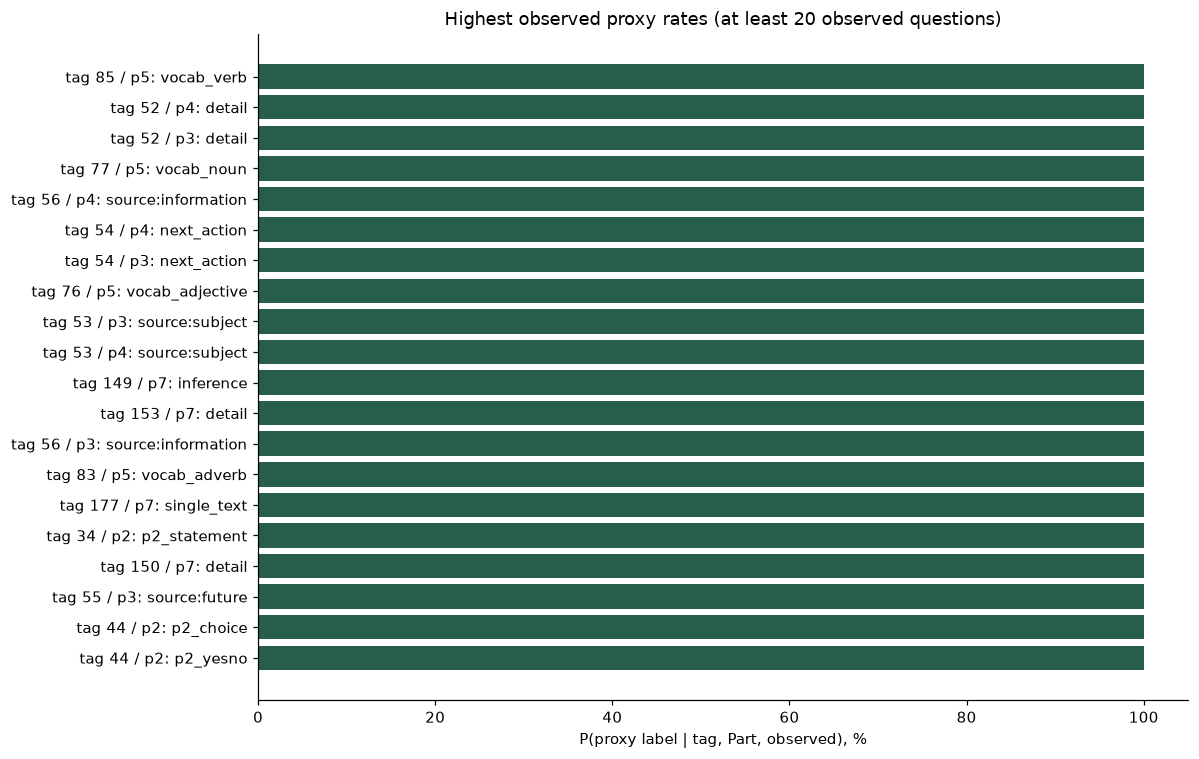

In [5]:
columns = ['tag_id','part','axis','label','hits','observed','precision_observed','observed_fraction','bridge_coverage','reference_bundle_support','recall_same_part_observed','lift']
ranked = rates.sort_values(['precision_observed','reference_bundle_support'], ascending=[False,False])
display(ranked[columns].head(30))
strong = ranked[(ranked.observed >= 20) & (ranked.axis != 'accent')].head(20).copy()
if len(strong):
    labels = strong.apply(lambda r: f"tag {r.tag_id} / {r.part}: {r.label}", axis=1)
    fig, ax = plt.subplots(figsize=(11,7))
    ax.barh(labels.iloc[::-1], strong.precision_observed.iloc[::-1]*100, color='#275d4b')
    ax.set(xlabel='P(proxy label | tag, Part, observed), %', title='Highest observed proxy rates (at least 20 observed questions)', xlim=(0,105))
    fig.tight_layout(); plt.show()

## 5. Độ phủ trên toàn EdNet

Biểu đồ phân biệt có ít nhất một đề xuất và mọi tag đã có đề xuất. Accent không tính thành kỹ năng. Không bỏ tag chưa rõ khỏi mẫu số.

,questions,any_semantic,any_descriptor,all_original_tags_semantic,any_semantic_or_unnamed_family
part,,,,,
all,13169,11844,11850,7052,11844
p1,643,589,589,0,589
p2,1662,1646,1646,0,1646
p3,1266,1254,1254,0,1254
p4,1158,1152,1158,0,1152
p5,5703,5140,5140,5140,5140
p6,1335,898,898,777,898
p7,1402,1165,1165,1135,1165


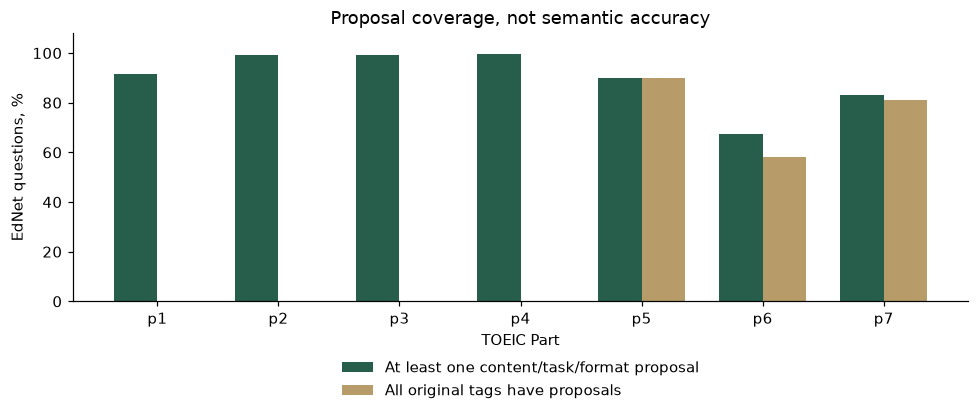

In [6]:
coverage = pd.DataFrame(summary['coverage']).set_index('part')
display(coverage)
p = coverage.drop(index='all')
x = np.arange(len(p)); fig, ax = plt.subplots(figsize=(9,4))
ax.bar(x-.18, p.any_semantic/p.questions*100, .36, label='At least one content/task/format proposal', color='#275d4b')
ax.bar(x+.18, p.all_original_tags_semantic/p.questions*100, .36, label='All original tags have proposals', color='#b79b68')
ax.set(xticks=x, xticklabels=p.index, xlabel='TOEIC Part', ylabel='EdNet questions, %', title='Proposal coverage, not semantic accuracy', ylim=(0,108))
ax.legend(loc='upper center', bbox_to_anchor=(.5,-.17), frameon=False)
fig.tight_layout(); plt.show()

## 6. Gom tag thành nhóm cha và nhóm yếu

Nhóm cùng nhãn thô giữ scope từng tag. Tag có thể nằm ở nhiều trục nên các nhóm có thể giao nhau: **không cộng số giảm như cluster rời nhau**. Nhóm yếu theo profile không tự nhận tên kỹ năng.

,cluster_id,kind,axis,label,members,status
0,parent:format:advertisement,same_coarse_label_parent,format,advertisement,"[146, 154]",candidate_parent_not_semantic_equivalence
1,parent:format:mail,same_coarse_label_parent,format,mail,"[147, 151, 155, 162, 164, 170]",candidate_parent_not_semantic_equivalence
2,parent:format:multi_text,same_coarse_label_parent,format,multi_text,"[147, 149, 154, 158, 161, 162, 163, 164, 165, ...",candidate_parent_not_semantic_equivalence
3,parent:format:single_text,same_coarse_label_parent,format,single_text,"[167, 168, 169, 177]",candidate_parent_not_semantic_equivalence
4,parent:format:source:passage_article,same_coarse_label_parent,format,source:passage_article,"[157, 161, 165]",candidate_parent_not_semantic_equivalence
5,parent:format:source:passage_form,same_coarse_label_parent,format,source:passage_form,"[152, 158, 163, 165, 170]",candidate_parent_not_semantic_equivalence
6,parent:format:source:passage_notice,same_coarse_label_parent,format,source:passage_notice,"[159, 164, 166, 174]",candidate_parent_not_semantic_equivalence
7,parent:format:source:passage_text,same_coarse_label_parent,format,source:passage_text,"[167, 168, 174]",candidate_parent_not_semantic_equivalence
8,parent:format:source:passage_webpage,same_coarse_label_parent,format,source:passage_webpage,"[170, 172, 174]",candidate_parent_not_semantic_equivalence
9,parent:grammar:comparison,same_coarse_label_parent,grammar,comparison,"[91, 100, 101, 102, 131]",candidate_parent_not_semantic_equivalence


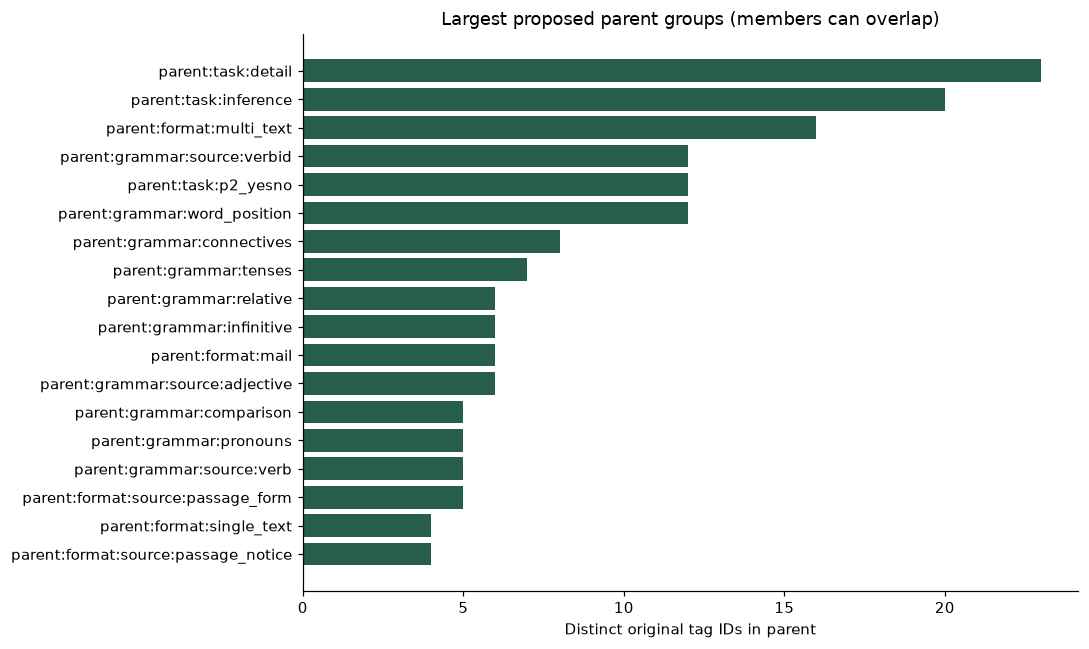

Tag/Part/axis units: 251
Distinct coarse axis-label units: 94
These are different resolutions, not a validated skill count.


In [7]:
clusters = pd.DataFrame(mapping['clusters'])
display(clusters[['cluster_id','kind','axis','label','members','status']])
parents = clusters[clusters.kind == 'same_coarse_label_parent'].copy()
parents['member_count'] = parents.members.map(len)
top = parents.sort_values('member_count', ascending=False).head(18)
if len(top):
    fig, ax = plt.subplots(figsize=(10,6))
    ax.barh(top.cluster_id.iloc[::-1], top.member_count.iloc[::-1], color='#275d4b')
    ax.set(xlabel='Distinct original tag IDs in parent', title='Largest proposed parent groups (members can overlap)')
    fig.tight_layout(); plt.show()
print('Tag/Part/axis units:', summary['named_tag_part_axis_units'])
print('Distinct coarse axis-label units:', summary['distinct_coarse_axis_labels'])
print('These are different resolutions, not a validated skill count.')

## 7. Đọc bằng chứng trước khi chốt

Thay TAG để xem một tag: tỷ lệ, scope, mẫu câu và lecture anchors. Câu proxy có đáp án nhưng chưa được chuyên gia gắn gold. Đừng dùng một mẫu để suy ra nghĩa toàn tag.

In [8]:
TAG = 3
record = next(r for r in mapping['tags'] if r['tag_id'] == TAG)
display(pd.DataFrame(record['mappings']))
examples = matched[matched.tags.map(lambda values: TAG in values)]
display(examples[['question_id','part','question','correct_text','source_raw']].head(8))
print('Tag has semantic proposal:', record['has_semantic_label'])
print('Reference question count:', record['reference_questions'])
print('Question bridge count:', record['bridge_questions'])

,tag_id,part,axis,label,source,status,lecture_count,lecture_ids,titles,source_raws,semantic_validated,historical_identity_verified,precision_observed
0,3,p1,topic,p1_work_care,lecture_metadata,lecture_anchor_pending_review,1,[l660],[Con người - Những tình huống liên quan đến ch...,[data/raw/santa/supplemental/raw/toeic_test_co...,False,False,None


,question_id,part,question,correct_text,source_raw


Tag has semantic proposal: True
Reference question count: 18
Question bridge count: 0


## 8. Hàng chờ duyệt và giới hạn

1. Duyệt nhóm cha trong config có đủ khái quát và cùng trục không.
2. Duyệt các tag chỉ có lecture, ít mẫu, near-tie, nhãn metadata content hoặc nhóm profile chưa tên.
3. Giữ unresolved khi thiếu dữ liệu.
4. Chạy kiểm thử và đánh giá độc lập trước khi chốt dictionary dùng cho mô hình.

In [9]:
pending = pd.DataFrame([{k:r[k] for k in ['tag_id','reference_questions','bridge_questions','has_semantic_label','has_any_descriptor','has_unnamed_family']} for r in mapping['tags']])
display(pending[~pending.has_semantic_label])
print('Gold accuracy:', summary['gold_accuracy'])
print((ROOT / 'docs/RESULTS.md').read_text(encoding='utf-8')[:3500])

,tag_id,reference_questions,bridge_questions,has_semantic_label,has_any_descriptor,has_unnamed_family
1,2,418,0,False,False,False
6,7,201,0,False,False,False
18,19,23,0,False,False,False
20,21,23,0,False,False,False
21,22,30,0,False,False,False
23,24,712,283,False,False,False
26,27,69,19,False,False,False
29,30,194,28,False,False,False
31,32,203,0,False,False,False
50,51,8,2,False,False,False


Gold accuracy: None
# Kết quả lượt chạy mới

File sinh từ pipeline hiện tại; không lấy số liệu hoặc nhãn từ báo cáo cũ.

Snapshot: `4b3bc468a01c1bcccae3acac2a27d322fa94360bc98bd121055988b3a6966161`

- EdNet: 13,169 câu, 188 tag.
- Santa: 5,500 lượt câu → 5,470 ID khác nhau.
- Trùng ID: 3,651; khớp ID + Part + đáp án: 3,650; thêm bundle chính xác: 3,648.
- Neo bài giảng ID + Part: 287.
- Tag có đề xuất nội dung/kỹ năng/định dạng: 163; có bất kỳ mô tả (kể cả accent): 168.
- Nhóm cha cùng nhãn thô: 60; nhóm profile chưa đặt tên: 0.

Tag được giữ riêng vì có neo thuộc tính mạnh: 181, 182, 183, 184, 185. Không chuyển giá trị giọng đọc sang Part khác.

## Độ phủ theo Part

Đếm câu có ít nhất một mô tả nội dung/kỹ năng/định dạng áp dụng đúng Part; không tính riêng accent là kỹ năng.

- all: 11844/13169 = 89.94%; mọi tag gốc có mô tả: 7052/13169.
- p1: 589/643 = 91.60%; mọi tag gốc có mô tả: 0/643.
- p2: 1646/1662 = 99.04%; mọi tag gốc có mô tả: 0/1662.
- p3: 1254/1266 = 99.05%; mọi tag gốc có